# 01 · Exploração e Validação dos Dados
Projeto **data-vigil** — detecção de anomalias em transações de cartão de crédito.

Este notebook cobre apenas a etapa de **exploração e validação** do dataset bruto. Pré-processamento, engenharia de atributos e modelagem ficam nos notebooks seguintes (`02_preprocessing`, `03_modelagem`, `04_avaliacao`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (8, 4)

## Carga e validação de integridade

In [2]:
df = pd.read_csv('../data/creditcard.csv')
print('Formato:', df.shape)
df.head()

Formato: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Checagens básicas de qualidade de dado
print('Valores nulos por coluna:')
print(df.isnull().sum().sum(), 'nulos no total')
print('\nLinhas duplicadas:', df.duplicated().sum())
print('\nTipos de dado:')
print(df.dtypes.value_counts())

Valores nulos por coluna:
0 nulos no total



Linhas duplicadas: 1081

Tipos de dado:
float64    30
int64       1
Name: count, dtype: int64


**Nota de qualidade**: o dataset apresenta linhas duplicadas (comum nesta versão pública do Credit Card Fraud Detection). Duplicatas não são removidas aqui de forma automática — a decisão e o tratamento ficam no notebook `02_preprocessing`, para manter a rastreabilidade entre dado bruto e dado tratado (padrão bronze → silver).

## Distribuição da variável-alvo (`Class`)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


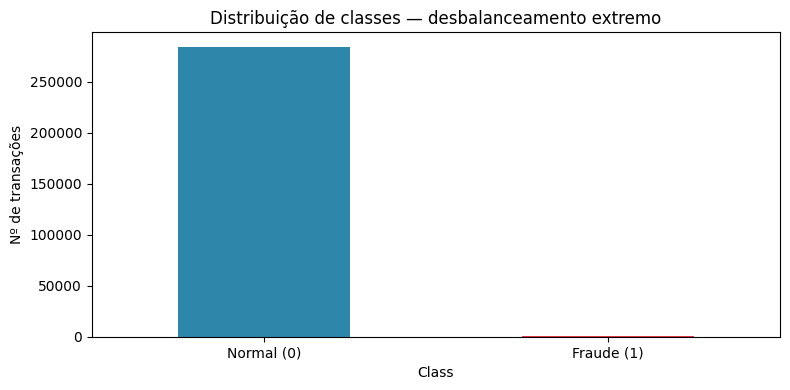

In [4]:
class_dist = df['Class'].value_counts(normalize=True) * 100
print(class_dist)

fig, ax = plt.subplots()
df['Class'].value_counts().plot(kind='bar', ax=ax, color=['#2E86AB', '#E63946'])
ax.set_xticklabels(['Normal (0)', 'Fraude (1)'], rotation=0)
ax.set_ylabel('Nº de transações')
ax.set_title('Distribuição de classes — desbalanceamento extremo')
plt.tight_layout()
plt.savefig('../reports/figures/01_class_distribution.png', dpi=110)
plt.show()

**Leitura**: apenas ~0,17% das transações são fraude. Qualquer modelo avaliado por acurácia pura vai parecer excelente e ser inútil na prática — por isso a métrica de referência deste projeto é **Recall / Precision / F1 / PR-AUC**, não acurácia (detalhado em `04_avaliacao`).

## Distribuição de `Amount` e `Time`

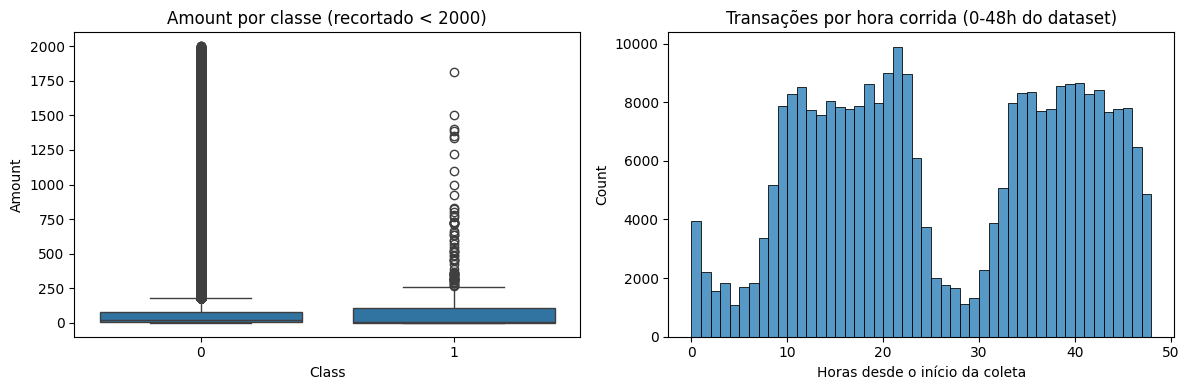

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='Class', y='Amount', data=df[df['Amount'] < 2000], ax=axes[0])
axes[0].set_title('Amount por classe (recortado < 2000)')
sns.histplot(df['Time'] / 3600, bins=48, ax=axes[1])
axes[1].set_title('Transações por hora corrida (0-48h do dataset)')
axes[1].set_xlabel('Horas desde o início da coleta')
plt.tight_layout()
plt.savefig('../reports/figures/02_amount_time.png', dpi=110)
plt.show()

## Correlação das variáveis PCA (`V1`–`V28`) com `Class`

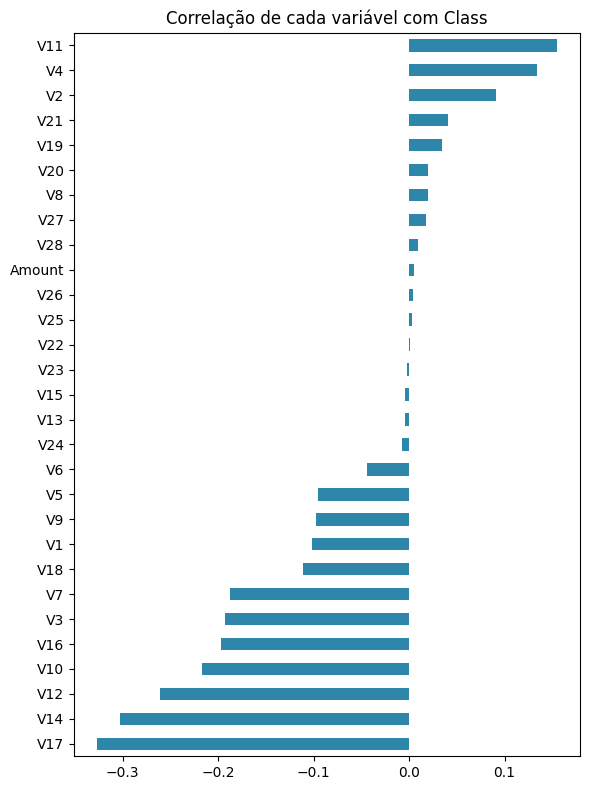

Top 5 variáveis mais correlacionadas (abs):
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
Name: Class, dtype: float64


In [6]:
corr = df.drop(columns=['Time']).corr()['Class'].drop('Class').sort_values()
fig, ax = plt.subplots(figsize=(6, 8))
corr.plot(kind='barh', ax=ax, color='#2E86AB')
ax.set_title('Correlação de cada variável com Class')
plt.tight_layout()
plt.savefig('../reports/figures/03_correlation_class.png', dpi=110)
plt.show()

print('Top 5 variáveis mais correlacionadas (abs):')
print(corr.abs().sort_values(ascending=False).head(5))

**Leitura**: mesmo com as variáveis anonimizadas via PCA, algumas (tipicamente `V17`, `V14`, `V12`, `V10` neste dataset) carregam forte poder discriminativo — vale a pena olhar de perto na etapa de explicabilidade (SHAP, em `04_avaliacao`).

## Conclusões da etapa de EDA

- Dataset com **284.807 linhas**, sem valores nulos, mas com linhas duplicadas a tratar.
- Desbalanceamento extremo (**0,17% de fraude**) — direciona toda a estratégia de avaliação e balanceamento do projeto.
- `Amount` tem cauda longa (poucas transações de valor muito alto) — candidato a transformação logarítmica.
- `Time` é um contador de segundos corridos, não um horário absoluto — mais útil transformado em hora do dia.
- Segue para `02_preprocessing.ipynb`.